# Final Project Dataloader

Downloads posts for the subreddits and date range you choose straight from the
[Arctic Shift](https://github.com/ArthurHeitmann/arctic_shift) search API and saves them as small local Parquet
files, one per subreddit per month.

- **Output format:** the same columns as `arctic_reddit_loader.ipynb`, saved under `data/<RUN_NAME>/raw/submissions/<YYYY-MM>/<subreddit>.parquet`.

## 0. Setup

In [68]:
%pip install -q pandas pyarrow tqdm matplotlib duckdb

Note: you may need to restart the kernel to use updated packages.


In [69]:
import json, os, time, urllib.parse, urllib.request
from pathlib import Path

import duckdb
import pandas as pd
import datetime as dt
import pandas_datareader.data as web    
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

print("pandas", pd.__version__, "| duckdb", duckdb.__version__)

pandas 2.2.2 | duckdb 1.5.6


## 1. Configuration

Edit this cell. Subreddit names are case-insensitive. Dates are inclusive months (`YYYY-MM`).

In [ ]:
SUBREDDITS = ["Economics", "economy", 'stocks']

START = "2022-01"          # inclusive, YYYY-MM
END   = "2026-02"          # inclusive, YYYY-MM

RUN_NAME = "econ_economy_api_v1"
DATA_DIR = Path("data") / RUN_NAME   # relative to this notebook

PAGE_SIZE     = 100        # posts per request (the API's usual maximum)
REQUEST_DELAY = 0.25       # seconds to pause between requests; raise it if you see errors
USER_AGENT    = "econ570-class-project"   # the API rejects Python's default user agent

# Columns kept in the output (same as the Hugging Face loader)
COLUMNS = ["id", "subreddit", "author", "created_utc", "created_at", "title", "selftext",
           "score", "num_comments", "url", "link_flair_text", "over_18"]

## 2. The download engine

`fetch_month` pages through one subreddit-month (oldest first, moving the `after` timestamp forward), removes
duplicates by post id, and returns a DataFrame. `pull_month` saves it under a temporary name and then renames it,
so a file exists only if that subreddit-month finished completely. Failed requests are retried with a growing wait.

In [ ]:
BASE = "https://arctic-shift.photon-reddit.com/api/posts/search"
RAW = DATA_DIR / "raw" / "submissions"
META = DATA_DIR / "_meta"
META.mkdir(parents=True, exist_ok=True)

def api_get(params, retries=5):
    url = BASE + "?" + urllib.parse.urlencode(params)
    for attempt in range(1, retries + 1):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})
            with urllib.request.urlopen(req, timeout=60) as r:
                return json.load(r)["data"]
        except Exception:
            if attempt == retries:
                raise
            time.sleep(min(5 * 2 ** (attempt - 1), 120))   # 5s, 10s, 20s ...

def month_range(start, end):
    return [p.strftime("%Y-%m") for p in pd.period_range(start, end, freq="M")]

def to_frame(rows):
    df = pd.DataFrame(rows).reindex(columns=[c for c in COLUMNS if c != "created_at"])
    df["created_at"] = pd.to_datetime(df["created_utc"], unit="s").astype("datetime64[us]")
    for c in ["id", "subreddit", "author", "title", "selftext", "url", "link_flair_text"]:
        df[c] = df[c].astype("string")
    df["selftext"] = df["selftext"].fillna("")
    for c in ["created_utc", "score", "num_comments"]:
        df[c] = df[c].fillna(0).astype("int64")
    df["over_18"] = df["over_18"].fillna(False).astype(bool)
    return df[COLUMNS].sort_values("created_utc").reset_index(drop=True)

def fetch_month(sub, month):
    # Return every post in `sub` for `month` ("YYYY-MM") as a DataFrame.
    start = pd.Timestamp(month + "-01")
    end = start + pd.offsets.MonthBegin(1)
    cur, rows = start.strftime("%Y-%m-%d"), {}
    while True:
        page = api_get({"subreddit": sub, "after": cur, "before": end.strftime("%Y-%m-%d"),
                        "limit": PAGE_SIZE, "sort": "asc"})
        time.sleep(REQUEST_DELAY)
        new = [p for p in page if p["id"] not in rows]
        for p in new:
            rows[p["id"]] = p
        if len(page) < PAGE_SIZE:
            break
        last = page[-1]["created_utc"]
        cur = last - 1 if new else last + 1   # -1 so posts sharing the last second aren't skipped
    return to_frame(list(rows.values()))



def out_path(sub, month):
    return RAW / month / f"{sub.lower()}.parquet"

def pull_month(sub, month):
    dst = out_path(sub, month)
    if dst.exists():
        return "skipped", 0
    dst.parent.mkdir(parents=True, exist_ok=True)
    df = fetch_month(sub, month)
    tmp = dst.with_suffix(".parquet.partial")
    df.to_parquet(tmp, index=False, compression="zstd")
    os.replace(tmp, dst)   # atomic: dst exists only when complete
    return "done", len(df)

## 3. Accessing Fred data

We will use the FRED datareader api to access the S&P 500 data which will serve as the baseline for the market.

In [146]:
end='2024-02'
# start date is two weeks ago
end_dt = pd.to_datetime(end)
start = end_dt - dt.timedelta(days=31)

sp = web.DataReader('SP500', 'fred', start=start, end=end_dt)
sp['pct_change'] = sp['SP500'].pct_change()
sp.head()

/var/folders/z4/4j8f00gx7m1_gxdmyxzz2b080000gn/T/ipykernel_40489/3556810826.py:7: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  sp['pct_change'] = sp['SP500'].pct_change()


,SP500,pct_change
DATE,,
2024-01-01,NaN,NaN
2024-01-02,4742.83,NaN
2024-01-03,4704.81,-0.008016
2024-01-04,4688.68,-0.003428
2024-01-05,4697.24,0.001826


## 4. Full pull

Set `GO = True` and run. You can interrupt and re-run to resume: finished subreddit-months are skipped.
Failures are listed in `_meta/failed.json`; re-run the cell to retry them.

Data is stored in parquet files because of its compressed column-like format. Because of the sheer volume of data we want to use for this project, this approach saves much more disk space than keeping all the data in a CSV.

In [133]:
GO = True

if GO:
    months = month_range(START, END)
    tasks = [(s, m) for m in months for s in SUBREDDITS if not out_path(s, m).exists()]
    print(f"{len(months) * len(SUBREDDITS)} subreddit-months in range, {len(tasks)} to fetch")
    kept, failed = 0, []
    bar = tqdm(tasks, unit="file")
    for sub, month in bar:
        bar.set_description(f"{sub} {month}")
        try:
            _, n = pull_month(sub, month)
            kept += n
            bar.set_postfix(rows_kept=f"{kept:,}")
        except Exception as e:
            failed.append((sub, month, f"{type(e).__name__}: {e}"))
    log = META / "failed.json"
    if failed:
        log.write_text(json.dumps(failed, indent=2))
        print(f"⚠️  {len(failed)} subreddit-month(s) failed; listed in {log}. Re-run this cell to retry them.")
    else:
        log.unlink(missing_ok=True)
        print(f"✓ all done ({kept:,} new rows this session)")
else:
    print("Set GO = True to start the full download.")

100 subreddit-months in range, 100 to fetch


economy 2022-03:   5%|▌         | 5/100 [02:43<51:45, 32.69s/file, rows_kept=8,519]    


KeyboardInterrupt: 

## 5. Load the data

Loading goes through DuckDB, so you can filter by date or subreddit before anything reaches pandas.

In [ ]:
def load_reddit(subreddits=None, start=None, end=None, columns=None, data_dir=DATA_DIR, drop_removed=False):
    glob = str(Path(data_dir) / "raw" / "submissions" / "*" / "*.parquet")
    where = ["1=1"]
    if subreddits:
        where.append("lower(subreddit) IN (" + ", ".join(f"'{s.lower()}'" for s in subreddits) + ")")
    if start:
        where.append(f"created_at >= TIMESTAMP '{start}'")
    if end:
        where.append(f"created_at < TIMESTAMP '{end}'")
    text = "trim(coalesce(title,'') || ' ' || CASE WHEN selftext IN ('[deleted]','[removed]') THEN '' ELSE coalesce(selftext,'') END)"
    removed = "(selftext IN ('[deleted]','[removed]') OR title IN ('[deleted]','[removed]','[deleted by user]'))"
    sel = "*" if columns is None else ", ".join(f'"{c}"' for c in columns)
    q = f'''
        SELECT {sel}, {text} AS text, {removed} AS is_removed
        FROM read_parquet('{glob}', union_by_name = true)
        WHERE {" AND ".join(where)}
        {"AND NOT " + removed if drop_removed else ""}
        ORDER BY created_at
    '''
    return duckdb.sql(q).df()

posts = load_reddit()
print(f"{len(posts):,} posts, {posts.created_at.min()} → {posts.created_at.max()}")
posts.head()

39,979 posts, 2010-01-01 00:10:07 → 2017-01-31 23:53:29


,id,subreddit,author,created_utc,created_at,title,selftext,score,num_comments,url,link_flair_text,over_18,text,is_removed
0,ake66,Economics,dieyoung,1262304607,2010-01-01 00:10:07,"For those who don't know, I present, The Mirac...",,4,3,http://en.wikipedia.org/wiki/Miracle_of_chile,None,False,"For those who don't know, I present, The Mirac...",False
1,ake7q,Economics,antediluvian,1262305024,2010-01-01 00:17:04,"Where we are, Where We're Heading: by K. Denni...",,1,0,http://market-ticker.org/archives/http://marke...,None,False,"Where we are, Where We're Heading: by K. Denni...",False
2,akebd,Economics,diggro,1262305895,2010-01-01 00:31:35,"George Carlin on paying high taxes: ""It made m...",,7,4,http://www.esquire.com/features/what-ive-learn...,None,False,"George Carlin on paying high taxes: ""It made m...",False
3,akelj,Economics,[deleted],1262308742,2010-01-01 01:19:02,The Media's Top 10 Worst Economic Myths of 2009,,0,0,http://businessandmedia.org/articles/2009/2009...,None,False,The Media's Top 10 Worst Economic Myths of 2009,False
4,akeug,Economics,[deleted],1262311426,2010-01-01 02:03:46,people and governments are now paying the pri...,[deleted],11,6,http://www.businessinsider.com/hsbc-chairman-s...,None,False,people and governments are now paying the pric...,True


## 6. Plotting post volume per subreddit vs the S&P 500

This function will output a graph showing the trend of the S&P 500 and subreddit average weekly post volume over a given period of time. This helps us motivate the primary piece of our project, which will look at sentiment over time compared the the market. Post volume is a proxy in this scenario where we wanted to see if there is some correlation between the two before continuing our project.

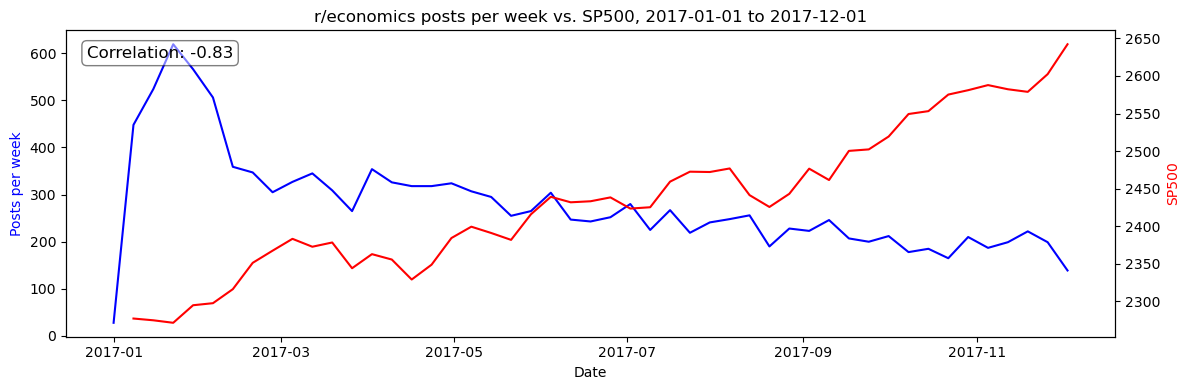

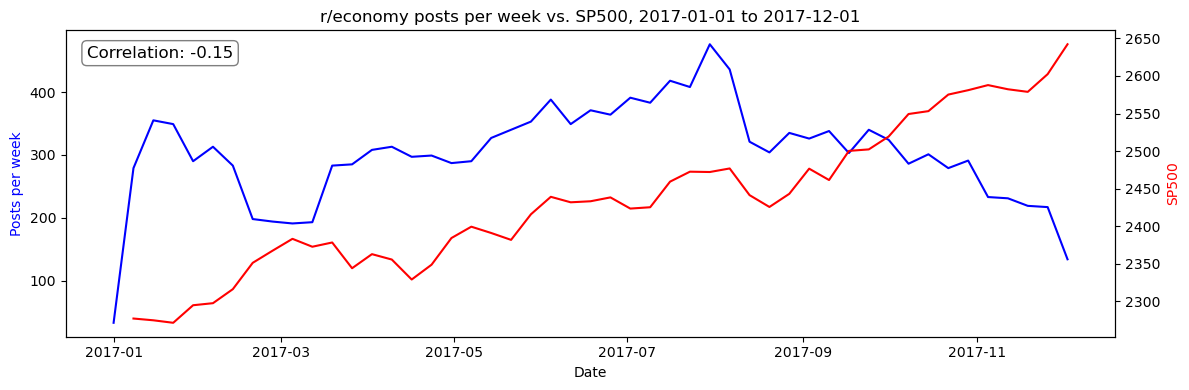

In [145]:
def sp_vs_posts(sub, start, end):
    df = load_reddit(subreddits=[sub], start=start, end=end)
    daily = df.set_index("created_at").resample("W").size().rename("posts")
    sp = web.DataReader('SP500', 'fred', start=start, end=end).resample("W").last()

    
    fig, ax1 = plt.subplots(figsize=(12, 4))
    ax1.plot(daily.index, daily.values, label="Posts per week", color='blue')
    ax1.set_ylabel("Posts per week", color="blue")
    ax1.set_xlabel("Date")

    ax2 = ax1.twinx()
    ax2.plot(sp.index, sp.values, label="SP500", color='red')
    ax2.set_ylabel("SP500", color="red")

    corr = daily.corr(sp["SP500"])

    ax1.set_title(f"r/{sub} posts per week vs. SP500, {start} to {end}")
    ax1.text(0.02, 0.95, f"Correlation: {corr:.2f}", transform=ax1.transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    fig.tight_layout()
    plt.show()


sp_vs_posts("economics", start="2017-01-01", end="2017-12-01")
sp_vs_posts("economy", start="2017-01-01", end="2017-12-01")